# DBTF Position Explorer

Click any labelled dot on the STM image to display the corresponding P_occ vs temperature curve(s).
All τ values available for that position are overlaid on the same axes.

## Setup
Set `NPY_DIR` to the folder containing the `.npy` files, and `IMAGE_PATH` to the STM screenshot.

In [2]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.gridspec import GridSpec
from pathlib import Path
import re

%matplotlib widget   

# ── USER CONFIG ───────────────────────────────────────────────────────────────
NPY_DIR    = Path('TemperatureData')        # folder containing the .npy files
IMAGE_PATH = Path('DBTF_PvsT_positions.png')   # STM screenshot with positions overlaid
# ─────────────────────────────────────────────────────────────────────────────

print('Imports OK')

Imports OK


## 1. Probability data — ASCII lists

These are the measured occupation probabilities, indexed by file number and τ.
The file number links to the `.npy` file that contains the corresponding temperature axis.

In [3]:
# Probability data keyed by (file_number, tau_seconds)
# Format: data_FILENUMBER_TIME  where 01->0.1s, 05->0.5s, 1->1s, 5->5s

# Date cut and paste from Freddie's email of Mon 08/06/2026 14:51

PROB_DATA = {
    (20, 0.1): [0,0,0,0,0,0,0,0.18,0.6,0.84,0.94,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (20, 5.0): [0,0,0,0,0,0,0.2,0.5,0.94,0.94,0.98,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (21, 0.1): [0,0,0,0,0,0,0,0.06,0.23,0.66,0.89,0.93,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (21, 1.0): [0,0,0,0,0,0,0,0,0.08,0.38,0.674,0.84,0.96,0.98,0.98,1,1,1,1,1,1],
    (22, 0.1): [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.3,0.74,0.84,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (22, 0.5): [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.06,0.22,0.56,0.84,0.96,0.98,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (24, 0.1): [0,0,0,0,0,0,0,0,0,0.02,0.32,0.7,0.84,0.86,0.92,0.98,1,0.98,1,1,1,1,1,1,1],
    (24, 5.0): [0,0,0,0,0,0,0,0,0,0,0,0,0.1,0.36,0.54,0.78,0.84,0.88,0.98,0.92,0.96,0.96,0.98,1,1],
    (25, 0.1): [0,0,0,0,0,0,0,0,0,0.06,0.08,0.48,0.7,0.72,0.94,0.92,0.92,0.98,0.98,0.96,1,1,0.98,1,1,1,1,1,1,1,1,1,1,1],
    (25, 0.5): [0,0,0,0,0,0,0,0,0,0,0,0.26,0.44,0.62,0.74,0.88,0.92,0.94,0.98,0.96,0.98,1,0.98,1,0.96,1,0.98,1,0.98,1,0.98,0.96,0.98,1],
    (26, 0.1): [0,0,0,0,0,0,0,0,0,0,0.06,0.16,0.54,0.84,0.8,0.88,0.88,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (26, 1.0): [0,0,0,0,0,0,0,0,0,0,0,0,0.08,0.26,0.5,0.66,0.8,0.9,0.94,0.92,0.94,0.96,0.96,0.98,1,0.96,1,1,0.98,1],
    (27, 0.1): [0,0,0,0,0,0,0,0,0.04,0.12,0.48,0.64,0.92,0.98,0.96,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (27, 0.5): [0,0,0,0,0,0,0,0,0,0.04,0.08,0.28,0.62,0.84,0.9,0.98,1,0.96,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (28, 0.1): [0,0,0,0,0,0,0,0,0,0,0,0.04,0.08,0.5,0.76,0.86,0.96,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (28, 1.0): [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.2,0.4,0.66,0.88,0.94,0.9,0.96,0.98,0.98,0.98,1,0.98,1,0.98,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (31, 1.0): [0,0,0,0,0,0,0,0,0,0,0,0,0,0.06,0.02,0.12,0.22,0.22,0.34,0.44,0.54,0.54,0.64,0.88,0.76,0.78,0.8,0.84,0.82,0.82,0.88,0.98,0.86,0.9,0.92,0.84,0.86,0.94,0.94,0.9,0.92,0.9,0.94,0.94,1,1,1,1,1,1],
    (31, 0.1): [0,0,0,0,0,0,0,0,0,0,0,0.06,0.1,0.26,0.36,0.48,0.76,0.76,0.78,0.84,0.96,0.92,0.94,0.98,0.98,0.98,0.98,0.98,0.98,1,1,0.98,0.98,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (32, 0.1): [0,0,0,0,0,0,0.04,0.22,0.42,0.7,0.84,0.96,0.96,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (32, 1.0): [0,0,0,0,0,0,0,0.04,0.16,0.54,0.86,0.9,1,1,0.98,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (33, 0.1): [0,0,0,0,0,0,0,0,0.04,0.12,0.48,0.78,0.86,0.84,0.92,0.9,0.94,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (33, 1.0): [0,0,0,0,0,0,0,0,0,0.04,0.04,0.24,0.54,0.8,0.8,0.94,0.98,0.96,0.98,1,1,0.98,1,1,1,1,1,1,1,1,1,1],
    (34, 1.0): [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.04,0.16,0.32,0.36,0.54,0.63,0.82,0.9,0.92,0.98,1,0.94,0.96,0.96,1,0.98,0.96,0.98,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (34, 0.1): [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.04,0.18,0.38,0.68,0.88,0.94,0.94,0.86,0.9,1,0.98,0.98,0.98,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (35, 0.1): [0,0,0.06,0.06,0.18,0.26,0.48,0.62,0.62,0.84,0.84,0.9,0.94,1,1,0.98,0.98,1,1,1,0.98],
    (35, 1.0): [0,0,0,0,0,0,0,0,0.04,0.1,0.32,0.42,0.62,0.755,0.92,0.98,0.98,1,1,1,0.98],
    (36, 0.1): [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.08,0.29,0.38,0.53,0.33,0.9,1,0.92,0.98,0.98,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (36, 1.0): [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.02,0.22,0.51,0.57,0.7,0.89,0.88,0.92,1,0.94,0.98,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (37, 0.1): [0.1,0.18,0.18,0.21,0.46,0.58,0.84,0.98,0.96,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (37, 1.0): [0.06,0.04,0.06,0.1,0.1,0.21,0.62,0.78,0.96,0.94,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1],
    (38, 1.0): [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.05,0.08,0.08,0.16,0.18,0.32,0.48,0.52,0.64,0.7,1],
    (38, 0.1): [0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.02,0.02,0.14,0.32,0.7,0.72,0.84,0.9,1,1,1,1,1,1,1,1],
}

print(f'Loaded {len(PROB_DATA)} datasets covering file numbers: '
      f'{sorted(set(k[0] for k in PROB_DATA.keys()))}')

Loaded 32 datasets covering file numbers: [20, 21, 22, 24, 25, 26, 27, 28, 31, 32, 33, 34, 35, 36, 37, 38]


## 2. Load temperature axes from .npy files

In [4]:
# Parse tau string -> seconds
def parse_tau(s):
    return {'0pt1': 0.1, '0pt5': 0.5, '1': 1.0, '5': 5.0}.get(s) or float(s)


# Load all npy files: TEMP_DATA[(filenum, tau)] = T array (ascending)
TEMP_DATA = {}
missing = []

for npy_path in sorted(NPY_DIR.glob('*.npy')):
    m = re.match(r'data(\d+)_([^_]+)_pos\d+\.npy', npy_path.name)
    if not m:
        continue
    filenum = int(m.group(1))
    tau     = parse_tau(m.group(2))
    arr     = np.load(npy_path)
    # T_asc   = arr[0][::-1]   # row 0 is descending; reverse to ascending
    T_asc=arr[0]
    TEMP_DATA[(filenum, tau)] = T_asc

print(f'Loaded {len(TEMP_DATA)} temperature arrays from {NPY_DIR}/')
for k in sorted(TEMP_DATA):
    T = TEMP_DATA[k]
    P = PROB_DATA.get(k)
    match = '✓' if P is not None and len(P) == len(T) else f'✗ (T={len(T)}, P={len(P) if P else "missing"})'
    print(f'  filenum={k[0]:3d}  τ={k[1]:4.1f}s  N={len(T):3d}  T={T[0]:.3f}-{T[-1]:.3f} K  {match}')

Loaded 32 temperature arrays from TemperatureData/
  filenum= 20  τ= 0.1s  N= 70  T=4.149-1.800 K  ✓
  filenum= 20  τ= 5.0s  N= 70  T=4.142-1.800 K  ✓
  filenum= 21  τ= 0.1s  N= 70  T=4.155-1.837 K  ✓
  filenum= 21  τ= 1.0s  N= 21  T=4.155-2.101 K  ✓
  filenum= 22  τ= 0.1s  N= 68  T=4.158-1.839 K  ✓
  filenum= 22  τ= 0.5s  N= 67  T=4.155-1.839 K  ✓
  filenum= 24  τ= 0.1s  N= 25  T=4.137-1.849 K  ✓
  filenum= 24  τ= 5.0s  N= 25  T=4.127-1.845 K  ✓
  filenum= 25  τ= 0.1s  N= 34  T=4.091-1.850 K  ✓
  filenum= 25  τ= 0.5s  N= 34  T=4.030-1.847 K  ✓
  filenum= 26  τ= 0.1s  N= 30  T=4.079-1.844 K  ✓
  filenum= 26  τ= 1.0s  N= 30  T=4.052-1.839 K  ✓
  filenum= 27  τ= 0.1s  N= 45  T=4.051-1.824 K  ✓
  filenum= 27  τ= 0.5s  N= 45  T=3.976-1.821 K  ✓
  filenum= 28  τ= 0.1s  N= 50  T=4.128-1.836 K  ✓
  filenum= 28  τ= 1.0s  N= 50  T=4.109-1.841 K  ✓
  filenum= 31  τ= 0.1s  N= 50  T=4.061-1.857 K  ✓
  filenum= 31  τ= 1.0s  N= 50  T=3.974-1.856 K  ✓
  filenum= 32  τ= 0.1s  N= 50  T=4.107-1.822 K  ✓

## 3. Set molecule positions on the STM image

Each entry maps a molecule label to:
- `(x, y)` — pixel coordinates of its dot on the screenshot
- `file_numbers` — which data file numbers belong to this position

Coordinates have been hardwired in place.


In [5]:
# Pixel coordinates (x, y) of each dot in the 967×647 STM image.
# Grouped by position cluster — molecules sharing a spatial location
# are listed under the same entry so all their datasets are co-plotted.
#
# You'll have to adjust these values if the image is rescaled or replaced.

POSITIONS = {
    'D31': {'xy': (127, 110), 'file_numbers': [31]},
    'D38': {'xy': (210, 110), 'file_numbers': [38]},
    'D34': {'xy': (281, 110), 'file_numbers': [34]},
    'D32': {'xy': (311, 110), 'file_numbers': [32]},
    'D27 / D28': {'xy': (350, 110), 'file_numbers': [27, 28]},
    'D33': {'xy': (428, 110), 'file_numbers': [33]},
    'D20 / D21 / D22': {'xy': (470, 110), 'file_numbers': [20, 21, 22]},
    'D24 / D25 / D26': {'xy': (570, 110), 'file_numbers': [24, 25, 26]},
    'D37': {'xy': (660, 110), 'file_numbers': [37]},
    'D36': {'xy': (730, 110), 'file_numbers': [36]},
    'D35': {'xy': (795, 110), 'file_numbers': [35]},
}

# Click radius in pixels: how close a click must be to register a hit
HIT_RADIUS = 35

print(f'Defined {len(POSITIONS)} clickable positions.')

TAU_COLORS = {
    0.1: '#e74c3c',   # red
    0.5: '#e67e22',   # orange
    1.0: '#2ecc71',   # green
    5.0: '#3498db',   # blue
}
TAU_LABELS = {t: f'τ = {t:.1f} s' for t in TAU_COLORS}

# Marker styles cycle if two datasets share the same τ (different file numbers)
MARKERS = ['o', 's', '^', 'D', 'v', 'p', 'h']

Defined 11 clickable positions.


## 4. Main interactive explorer

C:\Users\ppzpjm\AppData\Local\Temp\ipykernel_380\3015206771.py:128: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


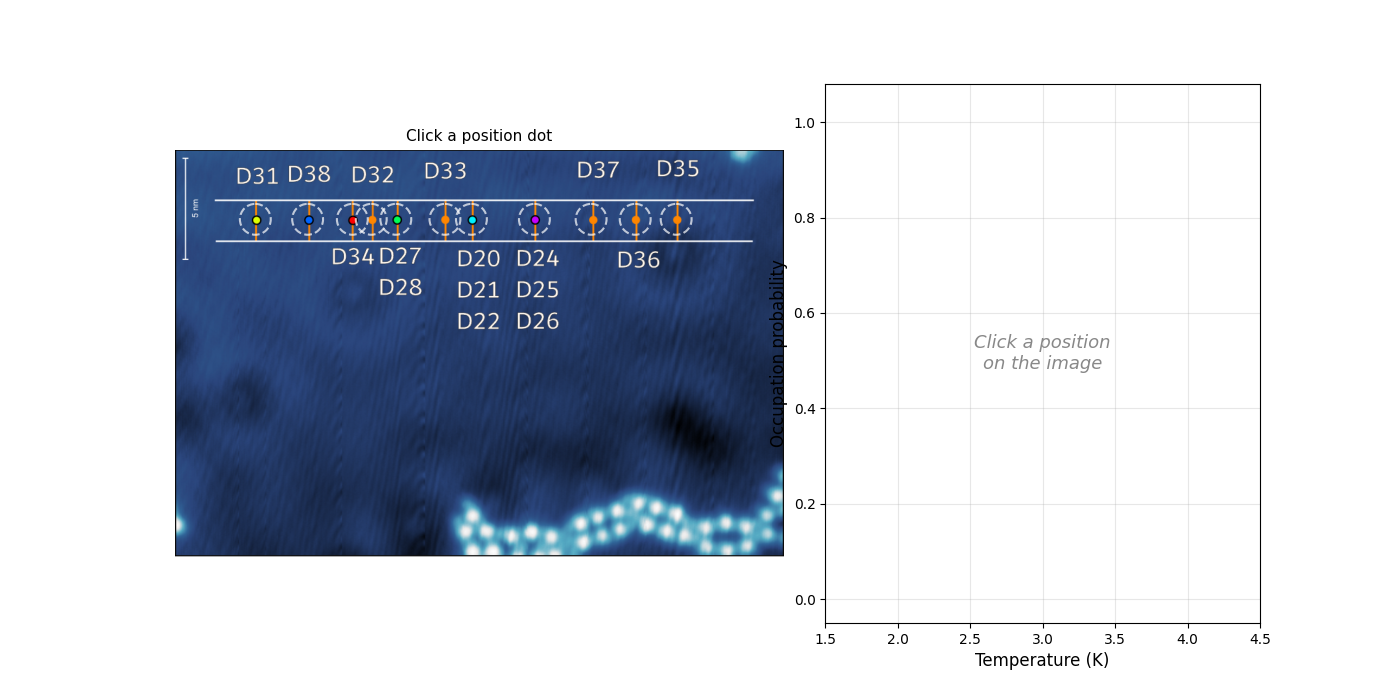

Explorer ready — click any position dot on the left panel.


In [6]:
img_raw = plt.imread(IMAGE_PATH)
ih, iw  = img_raw.shape[:2]

fig = plt.figure(figsize=(14, 7))
gs  = GridSpec(1, 2, figure=fig, width_ratios=[1.4, 1], wspace=0.08)

ax_img  = fig.add_subplot(gs[0])
ax_plot = fig.add_subplot(gs[1])

# ── Draw STM image ────────────────────────────────────────────────────────────
ax_img.imshow(img_raw)
ax_img.axis('off')
ax_img.set_title('Click a position dot', fontsize=11, pad=6)

# Draw clickable halos around each defined position
dot_artists = {}
for label, info in POSITIONS.items():
    x, y = info['xy']
    circle = plt.Circle((x, y), HIT_RADIUS * 0.7,
                         color='white', fill=False, linewidth=1.5, alpha=0.7,
                         linestyle='--')
    ax_img.add_patch(circle)
    dot_artists[label] = circle

# Highlight ring (shown on active selection)
highlight_ring = plt.Circle((0, 0), HIT_RADIUS * 0.85,
                              color='yellow', fill=False, linewidth=2.5, alpha=0,
                              zorder=10)
ax_img.add_patch(highlight_ring)


# ── Plot panel: initial state ─────────────────────────────────────────────────
ax_plot.set_xlabel('Temperature (K)', fontsize=12)
ax_plot.set_ylabel('Occupation probability', fontsize=12)
ax_plot.set_xlim(1.5, 4.5)
ax_plot.set_ylim(-0.05, 1.08)
ax_plot.grid(True, alpha=0.3)
status_text = ax_plot.text(
    0.5, 0.5, 'Click a position\non the image',
    transform=ax_plot.transAxes, ha='center', va='center',
    fontsize=13, color='#888888', style='italic'
)
title_text = ax_plot.set_title('', fontsize=12)


def plot_position(label):
    """Redraw the right-hand panel for the selected position label."""
    ax_plot.cla()
    ax_plot.set_xlabel('Temperature (K)', fontsize=12)
    ax_plot.set_ylabel('Occupation probability', fontsize=12)
    ax_plot.set_ylim(-0.05, 1.08)
    ax_plot.grid(True, alpha=0.3)
    ax_plot.set_title(label, fontsize=12, fontweight='bold')

    file_nums = POSITIONS[label]['file_numbers']

    # Collect all (tau, filenum, T, P) tuples available
    datasets = []
    for fnum in file_nums:
        for tau in sorted(TAU_COLORS):
            key = (fnum, tau)
            if key in PROB_DATA and key in TEMP_DATA:
                P = np.array(PROB_DATA[key])
                T = TEMP_DATA[key]
                N = min(len(T), len(P))
                if N > 0:
                    datasets.append((tau, fnum, T[:N], P[:N]))

    if not datasets:
        ax_plot.text(0.5, 0.5, 'No data found',
                     transform=ax_plot.transAxes, ha='center', va='center',
                     fontsize=12, color='red')
        return

    # Count how many datasets share each tau (for marker cycling)
    tau_count = {}
    for tau, fnum, T, P in datasets:
        tau_count[tau] = tau_count.get(tau, 0) + 1
    tau_seen  = {}

    all_T = np.concatenate([T for _, _, T, _ in datasets])
    ax_plot.set_xlim(max(1.5, all_T.min() - 0.1), min(5.0, all_T.max() + 0.1))

    for tau, fnum, T, P in datasets:
        color  = TAU_COLORS.get(tau, 'grey')
        idx    = tau_seen.get(tau, 0)
        marker = MARKERS[idx % len(MARKERS)]
        tau_seen[tau] = idx + 1

        # Label: include file number only when multiple files share this position
        lbl = f'τ = {tau:.1f} s'
        if len(file_nums) > 1:
            lbl += f'  (D{fnum})'

        ax_plot.plot(T, P, marker=marker, color=color, markersize=5,
                     linewidth=1.4, label=lbl, alpha=0.85)

    ax_plot.legend(fontsize=9, framealpha=0.9)


def on_click(event):
    if event.inaxes != ax_img or event.xdata is None:
        return
    cx, cy = event.xdata, event.ydata

    # Find closest position within hit radius
    best_label, best_dist = None, np.inf
    for label, info in POSITIONS.items():
        px, py = info['xy']
        dist = np.hypot(cx - px, cy - py)
        if dist < best_dist:
            best_dist  = dist
            best_label = label

    if best_dist > HIT_RADIUS:
        return   # miss — ignore

    # Move highlight ring
    hx, hy = POSITIONS[best_label]['xy']
    highlight_ring.center = (hx, hy)
    highlight_ring.set_alpha(0.95)

    plot_position(best_label)
    fig.canvas.draw_idle()


fig.canvas.mpl_connect('button_press_event', on_click)
plt.tight_layout()
plt.show()
print('Explorer ready — click any position dot on the left panel.')